# Model: Classification of a patient's cirrhosis stage
**Authors:** Deivid Matute / Marlon Vargas / Cristian Corella  | **Dataset:** [Cirrhosis Prediction Dataset (Kaggle, fedesoriano)](https://www.kaggle.com/fedesoriano/cirrhosis-prediction-dataset) — Mayo Clinic study on primary biliary cirrhosis | **Type:** classification (3 ordered classes)

This notebook follows the project template and leaves the model ready for the API (`models/cirrhosis.joblib` + `predictors/cirrhosis.py`).

Voice command: *"JarvisTEC, which cirrhosis stage is a 60 year old woman with ascites?"*

## 1. Problem analysis (0.5 pt)

**What do we want to predict?** The **stage** of the liver disease of a patient with primary biliary cirrhosis, from blood tests and the signs the doctor sees at the consultation. Stages go from 1 (mild damage) to 4 (established cirrhosis). It serves to answer commands such as *"JarvisTEC, which cirrhosis stage is the patient in?"*.

**Why does it matter?** The stage is determined with a liver **biopsy**, which is invasive. Dickson et al. (1989) showed with patients from this same study that age, bilirubin, albumin, prothrombin time and edema are enough to estimate the prognosis without a biopsy. Here we test whether measurements like those also allow estimating the stage.

**Why is it hard?** The stage describes the tissue seen under the microscope; blood tests only reflect it indirectly. In addition there are few patients (412) and a quarter of them are missing several tests.

**Design decisions**
- **Three ordered classes:** stage 1-2, stage 3 and stage 4. Stage 1 has only 21 patients and is merged with 2.
- **No information from the future:** follow-up days and the patient's outcome are not used (see the exploration).
- **Metrics:** accuracy (the three classes have similar sizes), macro F1 and **weighted kappa** (Cohen, 1968), which takes the order of the classes into account.
- **Success criterion:** beat the baseline that always answers the most frequent stage (38%) and make few serious errors (stage 1-2 ↔ stage 4).

## 2. Data understanding (0.5 pt)

The data comes from the Mayo Clinic study on primary biliary cirrhosis (1974–1984). Each row is a patient: 418, with 20 columns.

| Column | Meaning |
|---|---|
| `Stage` | **Target.** Disease stage (1 to 4), determined by biopsy |
| `Age`, `Sex` | Age (given in days) and sex |
| `Ascites`, `Hepatomegaly`, `Spiders`, `Edema` | Clinical signs: fluid in the abdomen, enlarged liver, spider angiomas on the skin and swelling (`N` no, `Y` yes; in `Edema`, `S` is mild or controlled) |
| `Bilirubin`, `Albumin`, `Prothrombin` | Bilirubin, albumin and clotting time: they measure how well the liver works |
| `Cholesterol`, `Copper`, `Alk_Phos`, `SGOT`, `Tryglicerides`, `Platelets` | Cholesterol, urine copper, alkaline phosphatase, SGOT enzyme, triglycerides and platelets |
| `N_Days`, `Status` | Follow-up days and outcome (`C` alive, `CL` transplanted, `D` deceased) |
| `Drug` | Treatment randomly assigned in the trial (D-penicillamine or placebo) |
| `ID` | Identifier |

In [1]:
import sys, warnings
warnings.filterwarnings('ignore')
sys.path.insert(0, '..')          # to import predictors/

import joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score, confusion_matrix

SEED = 42
BLUE, ORANGE, GRAY = '#2563eb', '#ea580c', '#94a3b8'
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 10, 'font.size': 9, 'legend.frameon': False})
print('scikit-learn', sklearn.__version__)

patients = pd.read_csv('../data/cirrhosis.csv')
print('Rows:', patients.shape[0], '| columns:', patients.shape[1], '| duplicates:', patients.duplicated().sum())
patients.head()

scikit-learn 1.8.0
Rows: 418 | columns: 20 | duplicates: 0


,ID,N_Days,Status,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
0,1,400,D,D-penicillamine,21464,F,Y,Y,Y,Y,14.5,261.0,2.60,156.0,1718.0,137.95,172.0,190.0,12.2,4.0
1,2,4500,C,D-penicillamine,20617,F,N,Y,Y,N,1.1,302.0,4.14,54.0,7394.8,113.52,88.0,221.0,10.6,3.0
2,3,1012,D,D-penicillamine,25594,M,N,N,N,S,1.4,176.0,3.48,210.0,516.0,96.10,55.0,151.0,12.0,4.0
3,4,1925,D,D-penicillamine,19994,F,N,Y,Y,S,1.8,244.0,2.54,64.0,6121.8,60.63,92.0,183.0,10.3,4.0
4,5,1504,CL,Placebo,13918,F,N,Y,Y,N,3.4,279.0,3.53,143.0,671.0,113.15,72.0,136.0,10.9,3.0


In [2]:
print(patients.dtypes.astype(str).to_dict(), '\n')
for col in ['Stage', 'Status', 'Drug', 'Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema']:
    print(f'{col:<13}', patients[col].value_counts(dropna=False).to_dict())
patients.describe().round(2)

{'ID': 'int64', 'N_Days': 'int64', 'Status': 'str', 'Drug': 'str', 'Age': 'int64', 'Sex': 'str', 'Ascites': 'str', 'Hepatomegaly': 'str', 'Spiders': 'str', 'Edema': 'str', 'Bilirubin': 'float64', 'Cholesterol': 'float64', 'Albumin': 'float64', 'Copper': 'float64', 'Alk_Phos': 'float64', 'SGOT': 'float64', 'Tryglicerides': 'float64', 'Platelets': 'float64', 'Prothrombin': 'float64', 'Stage': 'float64'} 

Stage         {3.0: 155, 4.0: 144, 2.0: 92, 1.0: 21, nan: 6}
Status        {'C': 232, 'D': 161, 'CL': 25}
Drug          {'D-penicillamine': 158, 'Placebo': 154, nan: 106}
Sex           {'F': 374, 'M': 44}
Ascites       {'N': 288, nan: 106, 'Y': 24}
Hepatomegaly  {'Y': 160, 'N': 152, nan: 106}
Spiders       {'N': 222, nan: 106, 'Y': 90}
Edema         {'N': 354, 'S': 44, 'Y': 20}


,ID,N_Days,Age,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
count,418.00,418.00,418.00,418.00,284.00,418.00,310.00,312.00,312.00,282.00,407.00,416.00,412.00
mean,209.50,1917.78,18533.35,3.22,369.51,3.50,97.65,1982.66,122.56,124.70,257.02,10.73,3.02
std,120.81,1104.67,3815.85,4.41,231.94,0.42,85.61,2140.39,56.70,65.15,98.33,1.02,0.88
min,1.00,41.00,9598.00,0.30,120.00,1.96,4.00,289.00,26.35,33.00,62.00,9.00,1.00
25%,105.25,1092.75,15644.50,0.80,249.50,3.24,41.25,871.50,80.60,84.25,188.50,10.00,2.00
50%,209.50,1730.00,18628.00,1.40,309.50,3.53,73.00,1259.00,114.70,108.00,251.00,10.60,3.00
75%,313.75,2613.50,21272.50,3.40,400.00,3.77,123.00,1980.00,151.90,151.00,318.00,11.10,4.00
max,418.00,4795.00,28650.00,28.00,1775.00,4.64,588.00,13862.40,457.25,598.00,721.00,18.00,4.00


## 3. Data exploration (0.5 pt)
Null values, variables that cannot be used, class balance and what changes with the stage.

In [3]:
nulls = patients.isna().sum()
print('Nulls per column:', nulls[nulls > 0].to_dict())
outside = patients.Drug.isna()
print('Patients who did not enter the trial (no Drug):', outside.sum(),
      '| nulls that belong to them:', int(patients[outside].isna().sum().sum()), 'of', int(nulls.sum()))

# What is known AFTER the exam: follow-up and outcome, by stage
print('\nFollow-up days (median) by stage:', patients.groupby('Stage').N_Days.median().to_dict())
print('% who died (Status = D) by stage:', (patients.groupby('Stage').Status.apply(lambda s: (s == 'D').mean()) * 100).round(0).to_dict())

Nulls per column: {'Drug': 106, 'Ascites': 106, 'Hepatomegaly': 106, 'Spiders': 106, 'Cholesterol': 134, 'Copper': 108, 'Alk_Phos': 106, 'SGOT': 106, 'Tryglicerides': 136, 'Platelets': 11, 'Prothrombin': 2, 'Stage': 6}
Patients who did not enter the trial (no Drug): 106 | nulls that belong to them: 969 of 1033

Follow-up days (median) by stage: {1.0: 2644.0, 2.0: 2409.5, 3.0: 1810.0, 4.0: 1207.0}
% who died (Status = D) by stage: {1.0: 10.0, 2.0: 25.0, 3.0: 31.0, 4.0: 58.0}


In [4]:
# Cleaning: no stage means no target; age in years; stages 1 and 2 together
CLASSES = ['stage 1-2', 'stage 3', 'stage 4']
NUMERIC = ['Age', 'Bilirubin', 'Cholesterol', 'Albumin', 'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin']
CATEGORICAL = ['Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema']

patients = patients.dropna(subset=['Stage']).reset_index(drop=True)
patients['Age'] = (patients.Age / 365.25).round(1)
stages = patients.Stage.astype(int).value_counts().sort_index()
patients['StageGroup'] = patients.Stage.map({1: 'stage 1-2', 2: 'stage 1-2', 3: 'stage 3', 4: 'stage 4'})
counts = patients.StageGroup.value_counts()[CLASSES]
print('Original stages:', stages.to_dict(), '-> classes:', counts.to_dict())
print('Skewness:', patients[NUMERIC].skew().round(1).to_dict())

Original stages: {1: 21, 2: 92, 3: 155, 4: 144} -> classes: {'stage 1-2': 113, 'stage 3': 155, 'stage 4': 144}
Skewness: {'Age': 0.1, 'Bilirubin': 2.7, 'Cholesterol': 3.4, 'Albumin': -0.5, 'Copper': 2.3, 'Alk_Phos': 3.0, 'SGOT': 1.4, 'Tryglicerides': 2.5, 'Platelets': 0.4, 'Prothrombin': 2.2}


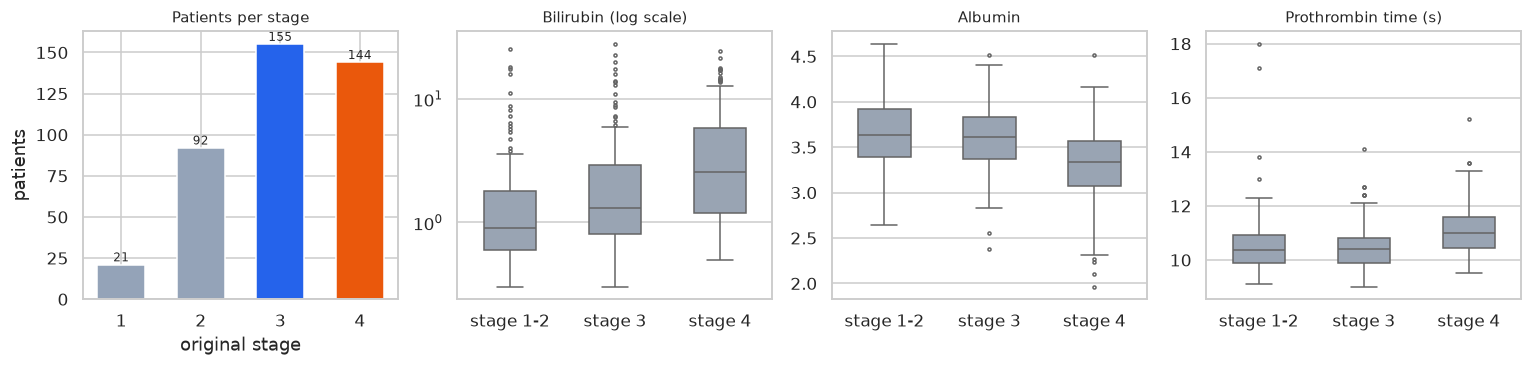

             Age  Bilirubin  Cholesterol  Albumin  Copper  Alk_Phos    SGOT  Tryglicerides  Platelets  Prothrombin
StageGroup                                                                                                        
stage 1-2   49.0       0.90        286.0     3.63    50.0    1087.0   99.00           97.0      275.0        10.35
stage 3     49.1       1.30        324.0     3.61    67.5    1257.5  112.38          119.0      252.0        10.40
stage 4     54.0       2.55        299.0     3.34    98.5    1428.0  122.45          106.0      216.0        11.00


In [5]:
# How many patients per stage and how three tests change
fig, ax = plt.subplots(1, 4, figsize=(14, 3.4))
ax[0].bar(stages.index.astype(str), stages.values, color=[GRAY, GRAY, BLUE, ORANGE], width=0.6)
for i, v in enumerate(stages.values): ax[0].text(i, v + 2, str(v), ha='center', fontsize=8)
ax[0].set_xlabel('original stage'); ax[0].set_ylabel('patients'); ax[0].set_title('Patients per stage')
for a, col, title in zip(ax[1:], ['Bilirubin', 'Albumin', 'Prothrombin'], ['Bilirubin (log scale)', 'Albumin', 'Prothrombin time (s)']):
    sns.boxplot(data=patients, x='StageGroup', y=col, order=CLASSES, ax=a, color=GRAY, width=0.5, fliersize=2)
    a.set_xlabel(''); a.set_ylabel(''); a.set_title(title)
ax[1].set_yscale('log')
plt.tight_layout(); plt.show()
print(patients.groupby('StageGroup')[NUMERIC].median().loc[CLASSES].round(2).to_string())

Ascites {'N': 31.0, 'Y': 88.0} | patients: {'N': 288, 'Y': 24}
Enlarged liver {'N': 14.0, 'Y': 55.0} | patients: {'Y': 160, 'N': 152}
Spider angiomas {'N': 27.0, 'Y': 56.0} | patients: {'N': 222, 'Y': 90}
Edema {'N': 30.0, 'S': 55.0, 'Y': 80.0} | patients: {'N': 348, 'S': 44, 'Y': 20}


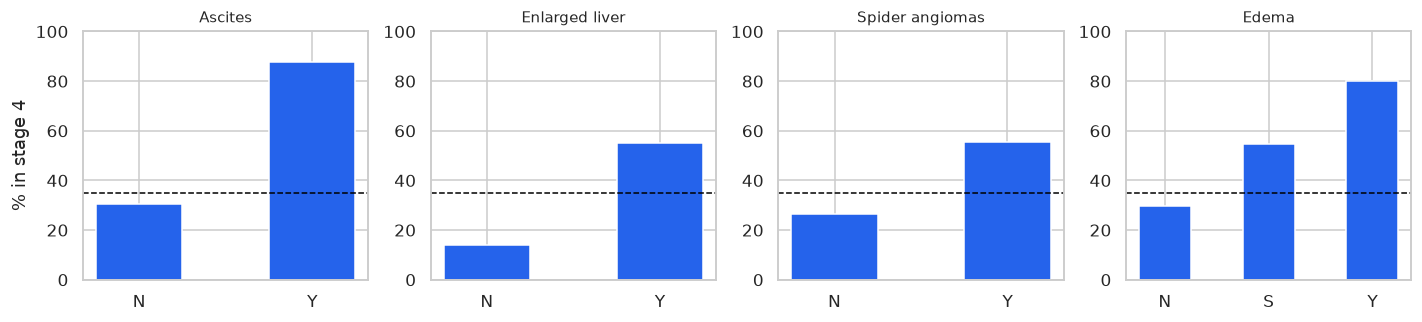

In [6]:
# Clinical signs: what percentage of the patients who have each sign is in stage 4
signs = {'Ascites': 'Ascites', 'Hepatomegaly': 'Enlarged liver', 'Spiders': 'Spider angiomas', 'Edema': 'Edema'}
fig, ax = plt.subplots(1, 4, figsize=(13, 3))
for a, (col, label) in zip(ax, signs.items()):
    t = patients.groupby(col).StageGroup.apply(lambda s: (s == 'stage 4').mean() * 100)
    a.bar(t.index, t.values, color=BLUE, width=0.5)
    a.axhline((patients.StageGroup == 'stage 4').mean() * 100, color='black', lw=1, ls='--')
    a.set_title(label); a.set_ylim(0, 100); a.set_ylabel('% in stage 4' if col == 'Ascites' else '')
    print(label, t.round(0).to_dict(), '| patients:', patients[col].value_counts().to_dict())
plt.tight_layout(); plt.show()

**Findings**
- **Nulls with a clear pattern:** 106 patients did not enter the trial and only the basic measurements were recorded for them; 969 of the 1,033 nulls belong to them. They are not removed (that would mean losing a quarter of the data): nulls are handled inside the `Pipeline`.
- **Variables that are not used.** `N_Days` and `Status` are what happened *after* the exam: in stage 4, 58% of the patients died and in stage 1, 10%. They say a lot about the stage, but they are not known for a new patient, so using them would be cheating. `Drug` was assigned at random and `ID` is an identifier.
- **Classes:** 6 patients have no stage and are removed (412 remain). Stage 1 has only 21, so it is merged with 2: 113, 155 and 144 patients remain.
- **Stage 4 stands out**: higher bilirubin (median 2.55 versus 0.90 in stage 1-2), lower albumin and platelets and slower clotting. **Stage 1-2 and 3 are hardly distinguishable** in the tests (albumin 3.63 versus 3.61; prothrombin 10.35 versus 10.40).
- The clinical signs point to stage 4: 88% of the patients with ascites and 80% of those with marked edema are in it, versus 35% overall. But they are infrequent signs (24 and 20 patients).
- Age is converted from days to years. Several tests are skewed and are log-transformed in the models that need it.

## 4. Model (2 pts)

**Split:** 75% training and 25% test, stratified.

**Algorithms compared**, tuned with `GridSearchCV` (5-fold stratified cross-validation repeated 3 times, optimizing accuracy):
- **Logistic regression:** linear reference. It needs to impute the nulls (median or mode), logarithm and standardization.
- **Random Forest** (Breiman, 2001), with the same imputation.
- **Histogram Gradient Boosting** (Friedman, 2001): it works with the nulls as they are, without imputing, which matters here because a quarter of the patients are missing tests.

All the preprocessing goes inside a `Pipeline`, so that it is fitted only with the training data.

In [7]:
X = patients[NUMERIC + CATEGORICAL]
y = patients['StageGroup']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
print('Training:', y_tr.value_counts()[CLASSES].to_dict(), '| test:', y_te.value_counts()[CLASSES].to_dict())

def with_imputation(model):
    """Imputes the nulls, applies the logarithm and scales (for logistic regression and Random Forest)."""
    numeric = Pipeline([('impute', SimpleImputer(strategy='median')),
                        ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                        ('scale', StandardScaler())])
    categorical = Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                            ('encode', OneHotEncoder(drop='if_binary', handle_unknown='ignore'))])
    prepare = ColumnTransformer([('numeric', numeric, NUMERIC), ('categorical', categorical, CATEGORICAL)])
    return Pipeline([('prepare', prepare), ('model', model)])

def without_imputation(model):
    """Leaves the nulls as they are: histogram Gradient Boosting handles them on its own."""
    encode = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=np.nan, encoded_missing_value=np.nan)
    prepare = ColumnTransformer([('numeric', 'passthrough', NUMERIC), ('categorical', encode, CATEGORICAL)])
    return Pipeline([('prepare', prepare), ('model', model)])

folds = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
cat_indices = list(range(len(NUMERIC), len(NUMERIC) + len(CATEGORICAL)))
grids = {
    'Logistic regression': (with_imputation(LogisticRegression(max_iter=5000)), {'model__C': [0.03, 0.1, 0.3, 1]}),
    'Random Forest':       (with_imputation(RandomForestClassifier(400, random_state=SEED, n_jobs=-1)),
                            {'model__min_samples_leaf': [2, 5, 10], 'model__max_features': ['sqrt', 0.5]}),
    'Gradient Boosting':   (without_imputation(HistGradientBoostingClassifier(random_state=SEED, categorical_features=cat_indices)),
                            {'model__learning_rate': [0.03, 0.1], 'model__max_depth': [2, 3], 'model__max_iter': [50, 100]}),
}
best = {}
for name, (p, grid) in grids.items():
    gs = GridSearchCV(p, grid, cv=folds, scoring='accuracy', n_jobs=-1).fit(X_tr, y_tr)
    best[name] = gs
    print(f'{name:20s} CV accuracy: {gs.best_score_:.3f} ± {gs.cv_results_["std_test_score"][gs.best_index_]:.3f} | best parameters: {gs.best_params_}')

Training: {'stage 1-2': 85, 'stage 3': 116, 'stage 4': 108} | test: {'stage 1-2': 28, 'stage 3': 39, 'stage 4': 36}


Logistic regression  CV accuracy: 0.529 ± 0.073 | best parameters: {'model__C': 0.1}


Random Forest        CV accuracy: 0.536 ± 0.047 | best parameters: {'model__max_features': 0.5, 'model__min_samples_leaf': 5}


Gradient Boosting    CV accuracy: 0.534 ± 0.049 | best parameters: {'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__max_iter': 100}


## 5. Evaluation (1 pt)
Metrics on the test set and confusion matrices. Since the classes have an order, besides accuracy the **weighted kappa** is used, which penalizes confusing stage 1-2 with 4 more than with 3, and those serious errors are counted.

In [8]:
def measure(actual, pred):
    actual, pred = np.asarray(actual), np.asarray(pred)
    serious = ((actual == 'stage 1-2') & (pred == 'stage 4')) | ((actual == 'stage 4') & (pred == 'stage 1-2'))
    return {'accuracy': accuracy_score(actual, pred), 'macro F1': f1_score(actual, pred, average='macro'),
            'weighted kappa': cohen_kappa_score(actual, pred, labels=CLASSES, weights='quadratic'),
            'serious errors (%)': serious.mean() * 100}

models = {'Baseline (always "stage 3")': DummyClassifier(strategy='most_frequent').fit(X_tr, y_tr),
          **{n: gs.best_estimator_ for n, gs in best.items()}}
test_table = pd.DataFrame({n: measure(y_te, m.predict(X_te)) for n, m in models.items()}).T.round(3)
cv_table = pd.Series({n: gs.best_score_ for n, gs in best.items()}, name='CV accuracy').round(3)
chosen = cv_table.idxmax()
print('Selected model (highest cross-validated accuracy):', chosen)
test_table

Selected model (highest cross-validated accuracy): Random Forest


,accuracy,macro F1,weighted kappa,serious errors (%)
"Baseline (always ""stage 3"")",0.379,0.183,0.000,0.000
Logistic regression,0.515,0.489,0.387,6.796
Random Forest,0.515,0.495,0.386,8.738
Gradient Boosting,0.524,0.515,0.359,9.709


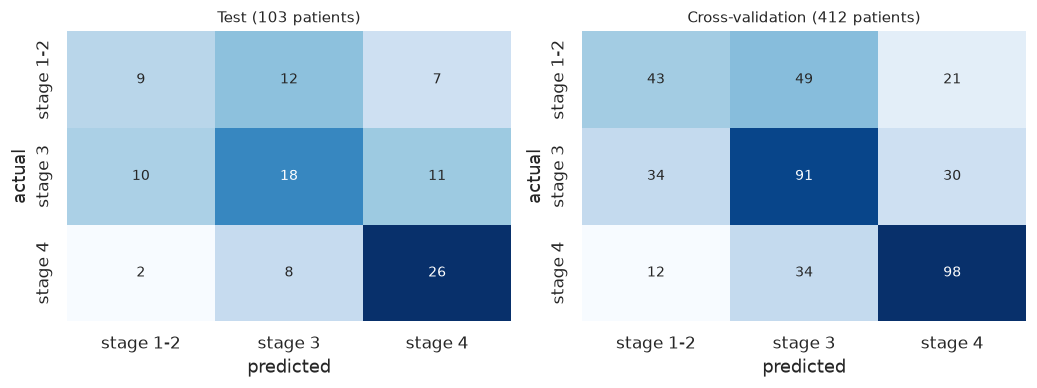

Cross-validation on all patients: {'accuracy': 0.563, 'macro F1': 0.549, 'weighted kappa': 0.426, 'serious errors (%)': 8.01}
Hits per class in cross-validation: {'stage 1-2': '43 of 113', 'stage 3': '91 of 155', 'stage 4': '98 of 144'}


In [9]:
final = models[chosen]
pred_te = final.predict(X_te)
pred_cv = cross_val_predict(final, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED))

fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.6))
for a, actual, pred, title in [(ax[0], y_te, pred_te, f'Test ({len(y_te)} patients)'),
                               (ax[1], y, pred_cv, f'Cross-validation ({len(y)} patients)')]:
    sns.heatmap(confusion_matrix(actual, pred, labels=CLASSES), annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=CLASSES, yticklabels=CLASSES, ax=a)
    a.set_xlabel('predicted'); a.set_ylabel('actual'); a.set_title(title)
plt.tight_layout(); plt.show()

cv_summary = measure(y, pred_cv)
print('Cross-validation on all patients:', {k: round(float(v), 3) for k, v in cv_summary.items()})
matrix = confusion_matrix(y, pred_cv, labels=CLASSES)
print('Hits per class in cross-validation:', {c: f'{matrix[i, i]} of {matrix[i].sum()}' for i, c in enumerate(CLASSES)})

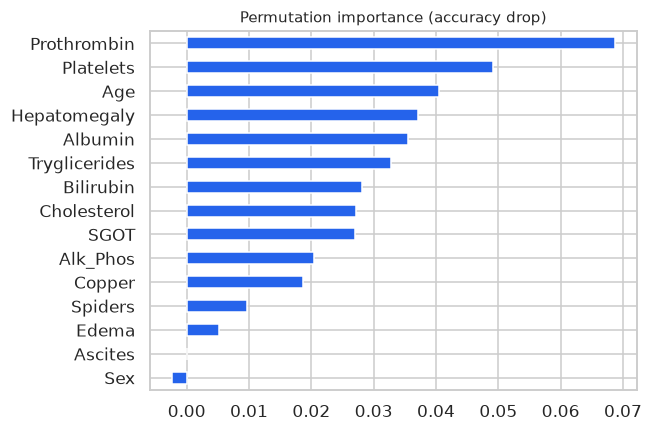

{'Prothrombin': 0.069, 'Platelets': 0.049, 'Age': 0.04, 'Hepatomegaly': 0.037, 'Albumin': 0.036, 'Tryglicerides': 0.033, 'Bilirubin': 0.028, 'Cholesterol': 0.027, 'SGOT': 0.027, 'Alk_Phos': 0.02, 'Copper': 0.019, 'Spiders': 0.01, 'Edema': 0.005, 'Ascites': 0.0, 'Sex': -0.002}


In [10]:
# Which variables weigh the most: how much the accuracy drops when each column is shuffled, measured on patients the model did not see
drops = []
for i_tr, i_va in StratifiedKFold(5, shuffle=True, random_state=SEED).split(X, y):
    m = clone(final).fit(X.iloc[i_tr], y.iloc[i_tr])
    drops.append(permutation_importance(m, X.iloc[i_va], y.iloc[i_va], scoring='accuracy', n_repeats=10,
                                        random_state=SEED).importances_mean)
importance = pd.Series(np.mean(drops, axis=0), index=X.columns).sort_values()
importance.plot.barh(figsize=(6, 4), color=BLUE, title='Permutation importance (accuracy drop)')
plt.tight_layout(); plt.show()
print(importance.sort_values(ascending=False).round(3).to_dict())

**Reading the results**
- **Choice:** the three models end up tied in cross-validation (0.537, 0.534 and 0.529, with a variation between folds of ±0.05). The Random Forest is chosen for having the highest accuracy, but any of the three would give a similar result.
- **Real but moderate improvement:** on the test set it gets 53% of the stages right versus 38% for the baseline, with a weighted kappa of 0.43 (0 would be guessing; 1, perfect agreement). In cross-validation over the 412 patients the numbers are almost the same (54% and 0.41), so they do not depend on the split.
- **Where it hits and where it does not:** it recognizes stage 4 well (97 of 144 in cross-validation; 27 of 36 on test) and so-so stage 3 (87 of 155), but only 38 of 113 patients in stage 1-2: almost half (54) go to stage 3, which is what the exploration anticipated.
- **Serious errors:** it confuses stage 1-2 with 4, or the other way around, in 7% of the patients.
- **What weighs the most:** prothrombin time, platelets, enlarged liver and age. They are signs of a liver that no longer works well, that is, of stage 4.

## 6. Conclusion (0.5 pt)

**How well does it work?** Better than guessing, but far from replacing the biopsy: it gets the stage right in a little more than half of the patients (53% on test, versus 38% for the baseline). Its useful part is **recognizing stage 4**, established cirrhosis, which it detects in two out of three cases.

**What was learned**
- The ceiling is moderate by nature: the stage is defined by looking at the tissue under the microscope, and blood only changes clearly when the liver is already failing. That is why the early stages cannot be told apart. It is not a defect of the algorithm: three very different models reach the same result.
- Checking which variables are known at prediction time avoided a serious mistake: follow-up days and outcome would have made the model look better, but they do not exist for a new patient.
- Merging stage 1 with 2 was necessary: 21 patients are not enough to learn a class.

**Limitations**
- There are 412 patients from a single center, from the 70s and 80s, and all with a rare disease (primary biliary cirrhosis); it cannot be applied to cirrhosis from other causes.
- Almost 90% are women.
- It is not a medical diagnosis. The API says so in every response.

**Possible improvements:** an ordinal model and, above all, measurements that reflect the tissue more directly.

## Export the model
The chosen model is **retrained with all the data** and saved together with the typical value of each variable, so the API can fill in what the user does not give.

In [11]:
final_model = clone(final).fit(X, y)

bundle = {
    'pipeline': final_model, 'model': chosen, 'features': list(X.columns), 'classes': CLASSES,
    'typical_values': {c: (round(float(X[c].median()), 2) if c in NUMERIC else str(X[c].mode()[0])) for c in X.columns},
    'categories': {c: sorted(map(str, X[c].dropna().unique())) for c in CATEGORICAL},
    'sklearn': sklearn.__version__,
    'cv_metrics': {'accuracy': float(cv_table[chosen])}, 'test_metrics': test_table.loc[chosen].to_dict(),
}
joblib.dump(bundle, '../models/cirrhosis.joblib', compress=3)
print('Saved ../models/cirrhosis.joblib | scikit-learn', sklearn.__version__)

# API contract check
from predictors.cirrhosis import predict
mild = {'Age': 45, 'Sex': 'F', 'Ascites': 'N', 'Hepatomegaly': 'N', 'Spiders': 'N', 'Edema': 'N',
        'Bilirubin': 0.7, 'Albumin': 3.9, 'Platelets': 300, 'Prothrombin': 10.0}
severe = {'Age': 60, 'Sex': 'F', 'Ascites': 'Y', 'Hepatomegaly': 'Y', 'Spiders': 'Y', 'Edema': 'Y',
          'Bilirubin': 6.0, 'Albumin': 2.8, 'Platelets': 150, 'Prothrombin': 12.5}
for name, patient in [('without signs', mild), ('with signs', severe)]:
    r = predict(patient)
    print(f'patient {name}: {r["prediction"]} | {r["probabilities"]}')
predict({})

Saved ../models/cirrhosis.joblib | scikit-learn 1.8.0
patient without signs: stage 1-2 | {'stage 1-2': 0.47, 'stage 3': 0.45, 'stage 4': 0.07}


patient with signs: stage 4 | {'stage 1-2': 0.04, 'stage 3': 0.03, 'stage 4': 0.93}


{'prediction': 'stage 3',
 'probabilities': {'stage 1-2': 0.23, 'stage 3': 0.64, 'stage 4': 0.13},
 'imputed_fields': ['Age',
  'Bilirubin',
  'Cholesterol',
  'Albumin',
  'Copper',
  'Alk_Phos',
  'SGOT',
  'Tryglicerides',
  'Platelets',
  'Prothrombin',
  'Sex',
  'Ascites',
  'Hepatomegaly',
  'Spiders',
  'Edema'],
 'model': 'Random Forest',
 'note': 'Indicative only: the real stage is determined by a biopsy. Not a medical diagnosis.'}